<a href="https://colab.research.google.com/github/Tushar-3512/Data-Science-Practical-/blob/main/Practical12.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

np.random.seed(42)
plt.rcParams["figure.figsize"] = (9, 4)
plt.rcParams["axes.grid"] = True

PART A: Implement Metropolis Algotihm

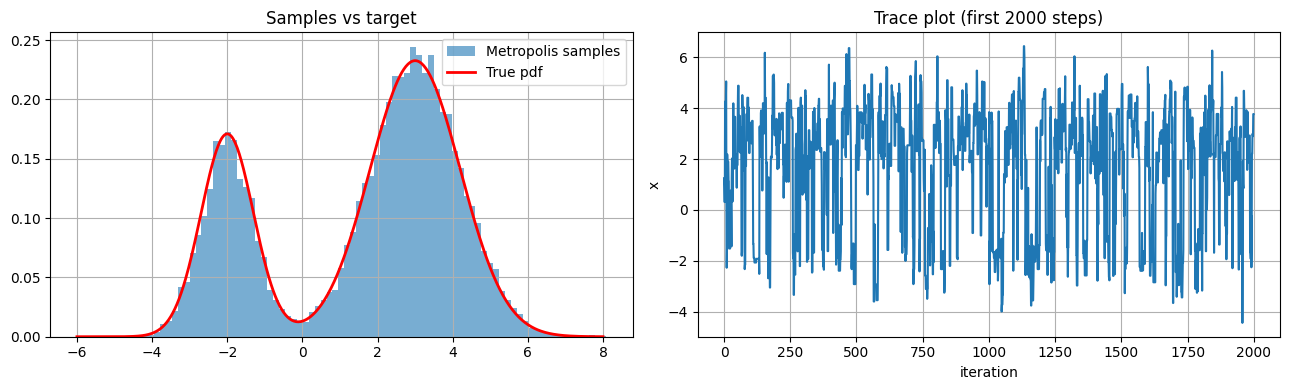

Ran 50000 steps (burn-in 5000) with step size 2.5; acceptance rate = 52.37%.
Sample mean = 1.574 (true 1.500), sample std = 2.527 (true 2.531).
The histogram closely follows the bimodal target, so the chain visits both modes correctly.


In [3]:
#Metropolis Algorithm
# Target: mixture of two Gaussians. Metropolis only needs ratios, so normalisation doesn't matter.
def target_pdf(x):
    g1 = np.exp(-0.5*((x+2)/0.7)**2)/(0.7*np.sqrt(2*np.pi))
    g2 = np.exp(-0.5*((x-3)/1.2)**2)/(1.2*np.sqrt(2*np.pi))
    return 0.3*g1 + 0.7*g2

def metropolis(target, n_samples, x0, step):
    samples = np.empty(n_samples)
    x, px = x0, target(x0)
    accepted = 0
    for i in range(n_samples):
        x_new = x + step*np.random.randn()       # symmetric proposal
        p_new = target(x_new)
        if np.random.rand() < p_new/px:          # accept with prob min(1, ratio)
            x, px = x_new, p_new
            accepted += 1
        samples[i] = x
    return samples, accepted/n_samples

n, burn = 50000, 5000
chain, acc = metropolis(target_pdf, n, x0=0.0, step=2.5)
post = chain[burn:]

xs = np.linspace(-6, 8, 500)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].hist(post, bins=80, density=True, alpha=0.6, label="Metropolis samples")
ax[0].plot(xs, target_pdf(xs), "r", lw=2, label="True pdf")
ax[0].set_title("Samples vs target"); ax[0].legend()
ax[1].plot(chain[:2000]); ax[1].set_title("Trace plot (first 2000 steps)")
ax[1].set_xlabel("iteration"); ax[1].set_ylabel("x")
plt.tight_layout(); plt.show()

true_mean = 0.3*(-2) + 0.7*3
true_std = np.sqrt(0.3*(0.7**2+4) + 0.7*(1.2**2+9) - true_mean**2)
print(f"Ran {n} steps (burn-in {burn}) with step size 2.5; acceptance rate = {acc:.2%}.")
print(f"Sample mean = {post.mean():.3f} (true {true_mean:.3f}), sample std = {post.std():.3f} (true {true_std:.3f}).")
print("The histogram closely follows the bimodal target, so the chain visits both modes correctly.")

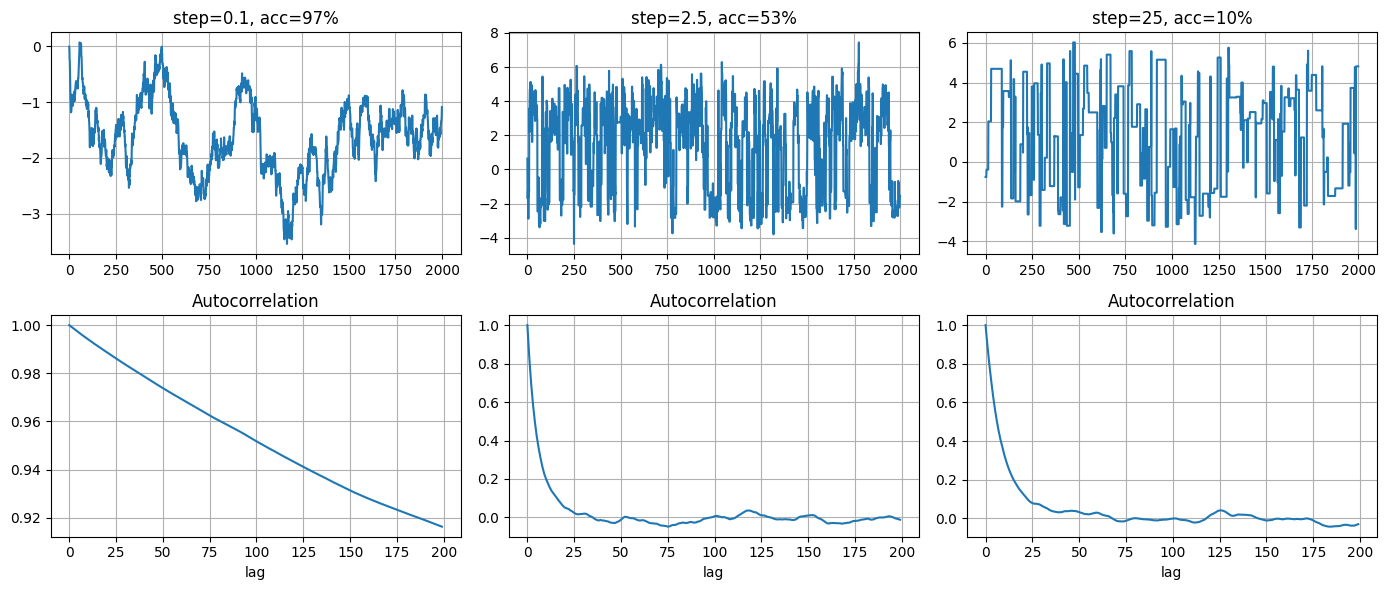

Step 0.1 accepts 97% of moves but is highly correlated (lag-1 ac = 0.999): it explores slowly.
Step 2.5 gives acceptance 53% with lag-1 ac = 0.833: a good balance.
Step 25 accepts only 10% of moves, so the chain gets stuck. Moderate steps (acceptance ~20-50%) mix best.


In [4]:
def autocorr(x, max_lag=200):
    x = x - x.mean()
    f = np.fft.rfft(x, n=2*len(x))
    ac = np.fft.irfft(f*np.conj(f))[:max_lag]
    return ac/ac[0]

steps = [0.1, 2.5, 25]
fig, ax = plt.subplots(2, 3, figsize=(14, 6))
results = []
for j, s in enumerate(steps):
    c, a = metropolis(target_pdf, 20000, 0.0, s)
    ac = autocorr(c[2000:])
    results.append((s, a, ac[1]))
    ax[0, j].plot(c[:2000]); ax[0, j].set_title(f"step={s}, acc={a:.0%}")
    ax[1, j].plot(ac); ax[1, j].set_title("Autocorrelation"); ax[1, j].set_xlabel("lag")
plt.tight_layout(); plt.show()

print(f"Step 0.1 accepts {results[0][1]:.0%} of moves but is highly correlated (lag-1 ac = {results[0][2]:.3f}): it explores slowly.")
print(f"Step 2.5 gives acceptance {results[1][1]:.0%} with lag-1 ac = {results[1][2]:.3f}: a good balance.")
print(f"Step 25 accepts only {results[2][1]:.0%} of moves, so the chain gets stuck. Moderate steps (acceptance ~20-50%) mix best.")

PART B: Deterministic Model

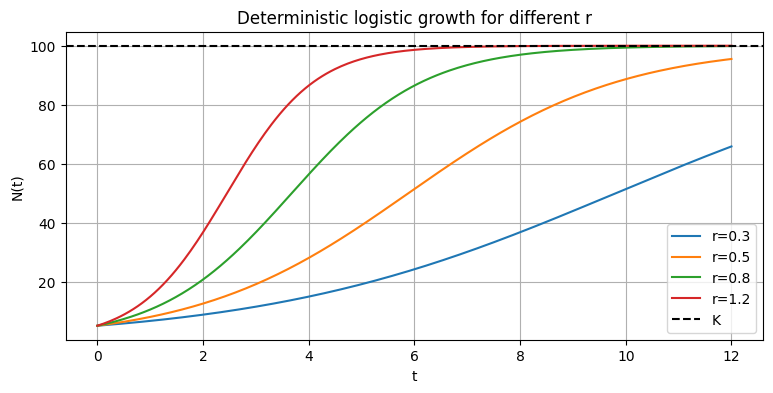

Logistic ODE simulated with r=0.8, K=100.0, N0=5.0; N(t) rises in an S-curve towards K.
Numerical (solve_ivp) vs analytic solution max error = 3.34e-07.
Re-running gives identical output (max difference = 0.0), confirming determinism.
Larger r makes the population reach the carrying capacity K faster, but K itself is unchanged.


In [6]:
def logistic_rhs(t, N, r, K):
    return r*N*(1 - N/K)

def logistic_analytic(t, N0, r, K):
    return K/(1 + ((K - N0)/N0)*np.exp(-r*t))

def simulate(r, K, N0, t_eval):
    sol = solve_ivp(logistic_rhs, (t_eval[0], t_eval[-1]), [N0], t_eval=t_eval,
                    args=(r, K), rtol=1e-9, atol=1e-9)
    return sol.y[0]

r_true, K_true, N0 = 0.8, 100.0, 5.0
t_fine = np.linspace(0, 12, 300)

N_num  = simulate(r_true, K_true, N0, t_fine)
N_ana  = logistic_analytic(t_fine, N0, r_true, K_true)
N_num2 = simulate(r_true, K_true, N0, t_fine)    # run again -> identical = deterministic

plt.figure()
for r in [0.3, 0.5, 0.8, 1.2]:
    plt.plot(t_fine, logistic_analytic(t_fine, N0, r, K_true), label=f"r={r}")
plt.axhline(K_true, color="k", ls="--", label="K")
plt.title("Deterministic logistic growth for different r")
plt.xlabel("t"); plt.ylabel("N(t)"); plt.legend(); plt.show()

print(f"Logistic ODE simulated with r={r_true}, K={K_true}, N0={N0}; N(t) rises in an S-curve towards K.")
print(f"Numerical (solve_ivp) vs analytic solution max error = {np.max(np.abs(N_num - N_ana)):.2e}.")
print(f"Re-running gives identical output (max difference = {np.max(np.abs(N_num - N_num2)):.1f}), confirming determinism.")
print("Larger r makes the population reach the carrying capacity K faster, but K itself is unchanged.")

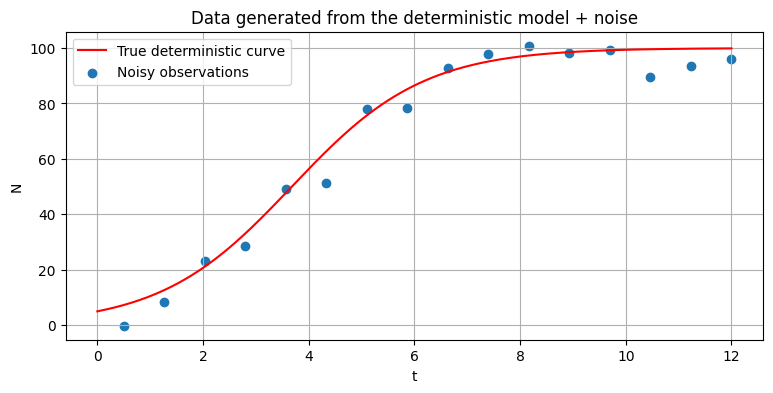

Generated 16 observations from the true curve with Gaussian noise (sigma=4.0).
The data scatter around the S-curve, mimicking real measurements.
Goal: recover the unknown r and K from this noisy data using Metropolis.


In [8]:
sigma = 4.0
t_obs = np.linspace(0.5, 12, 16)
N_obs = logistic_analytic(t_obs, N0, r_true, K_true) + sigma*np.random.randn(len(t_obs))

plt.figure()
plt.plot(t_fine, N_ana, "r", label="True deterministic curve")
plt.scatter(t_obs, N_obs, label="Noisy observations")
plt.title("Data generated from the deterministic model + noise")
plt.xlabel("t"); plt.ylabel("N"); plt.legend(); plt.show()

print(f"Generated {len(t_obs)} observations from the true curve with Gaussian noise (sigma={sigma}).")
print("The data scatter around the S-curve, mimicking real measurements.")
print("Goal: recover the unknown r and K from this noisy data using Metropolis.")

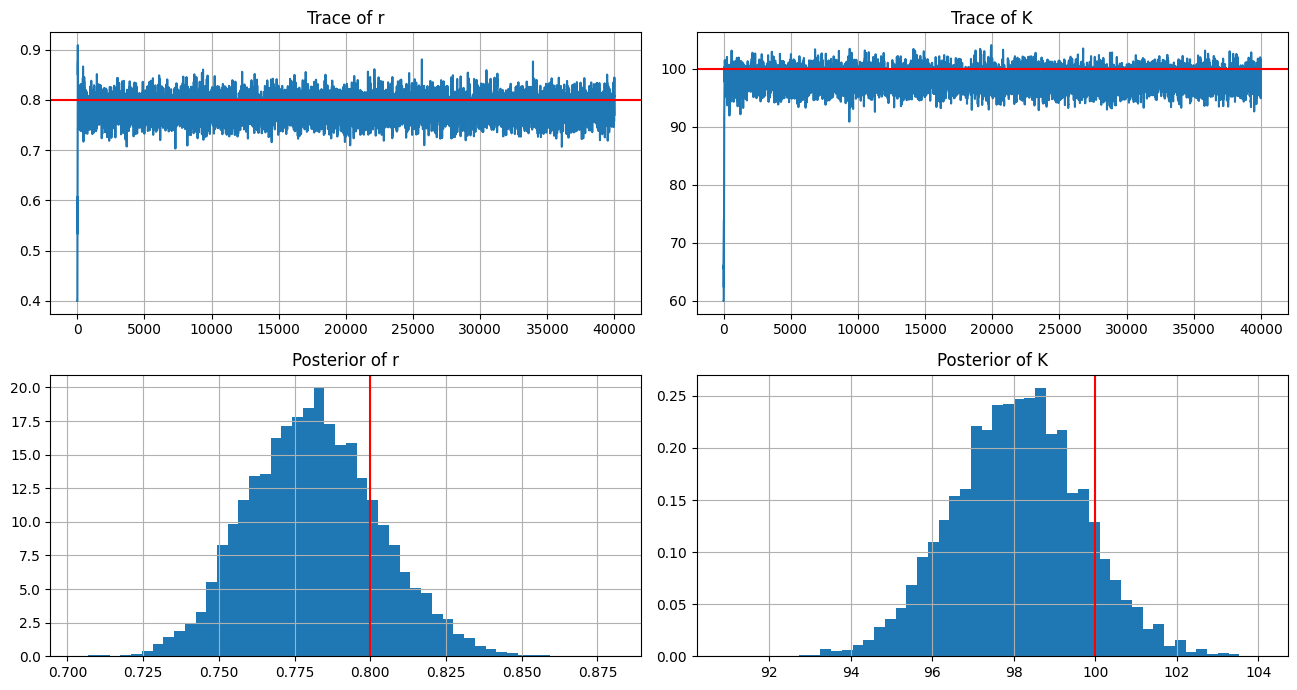

Ran 40000 steps (burn-in 5000), acceptance rate = 24.84%.
Posterior mean r = 0.781 (true 0.8), 95% interval [0.742, 0.825].
Posterior mean K = 98.09 (true 100.0), 95% interval [94.99, 101.21].
Traces settle quickly around the true values, showing the chain converged.


In [9]:
def log_posterior(theta):
    r, K = theta
    if not (0 < r < 3 and 0 < K < 300):       # uniform priors
        return -np.inf
    pred = logistic_analytic(t_obs, N0, r, K)
    return -0.5*np.sum((N_obs - pred)**2)/sigma**2

def metropolis_nd(log_post, theta0, n_samples, steps):
    theta = np.array(theta0, float)
    lp = log_post(theta)
    chain = np.empty((n_samples, len(theta)))
    acc = 0
    for i in range(n_samples):
        prop = theta + steps*np.random.randn(len(theta))
        lp_new = log_post(prop)
        if np.log(np.random.rand()) < lp_new - lp:
            theta, lp = prop, lp_new
            acc += 1
        chain[i] = theta
    return chain, acc/n_samples

chain, acc = metropolis_nd(log_posterior, [0.4, 60.0], 40000, np.array([0.05, 3.0]))
burn = 5000
post = chain[burn:]

fig, ax = plt.subplots(2, 2, figsize=(13, 7))
ax[0,0].plot(chain[:,0]); ax[0,0].axhline(r_true, color="r"); ax[0,0].set_title("Trace of r")
ax[0,1].plot(chain[:,1]); ax[0,1].axhline(K_true, color="r"); ax[0,1].set_title("Trace of K")
ax[1,0].hist(post[:,0], bins=50, density=True); ax[1,0].axvline(r_true, color="r"); ax[1,0].set_title("Posterior of r")
ax[1,1].hist(post[:,1], bins=50, density=True); ax[1,1].axvline(K_true, color="r"); ax[1,1].set_title("Posterior of K")
plt.tight_layout(); plt.show()

r_lo, r_hi = np.percentile(post[:,0], [2.5, 97.5])
K_lo, K_hi = np.percentile(post[:,1], [2.5, 97.5])
print(f"Ran 40000 steps (burn-in {burn}), acceptance rate = {acc:.2%}.")
print(f"Posterior mean r = {post[:,0].mean():.3f} (true {r_true}), 95% interval [{r_lo:.3f}, {r_hi:.3f}].")
print(f"Posterior mean K = {post[:,1].mean():.2f} (true {K_true}), 95% interval [{K_lo:.2f}, {K_hi:.2f}].")
print("Traces settle quickly around the true values, showing the chain converged.")

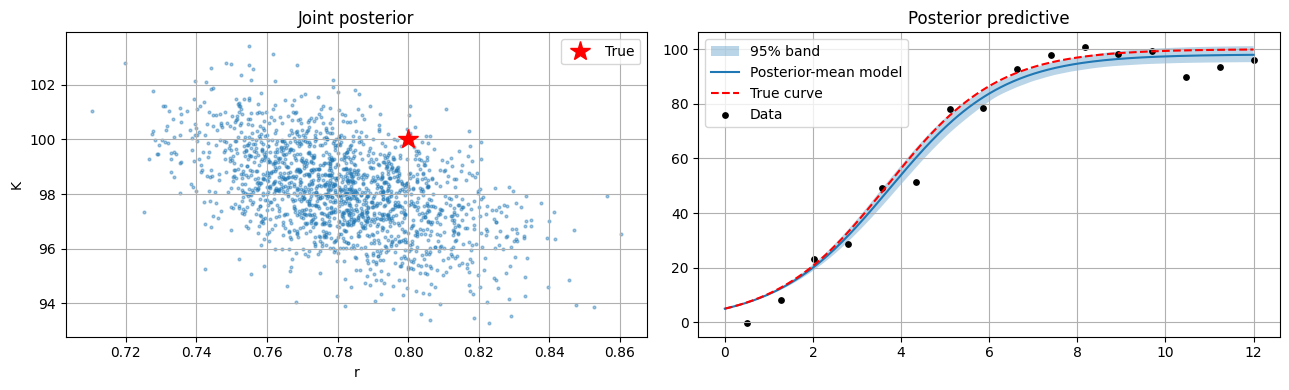

r and K are correlated in the posterior (corr = -0.47): a faster r can trade off against a smaller K.
The fitted deterministic curve (r=0.781, K=98.1) closely matches the true curve.
82% of the true curve lies inside the 95% posterior band, so the calibration is reliable.


In [11]:
idx = np.random.choice(len(post), 300, replace=False)
curves = np.array([logistic_analytic(t_fine, N0, *post[i]) for i in idx])
lo, hi = np.percentile(curves, [2.5, 97.5], axis=0)
mean_params = post.mean(axis=0)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].scatter(post[::20,0], post[::20,1], s=4, alpha=0.4)
ax[0].plot(r_true, K_true, "r*", ms=15, label="True")
ax[0].set_xlabel("r"); ax[0].set_ylabel("K"); ax[0].set_title("Joint posterior"); ax[0].legend()
ax[1].fill_between(t_fine, lo, hi, alpha=0.3, label="95% band")
ax[1].plot(t_fine, logistic_analytic(t_fine, N0, *mean_params), label="Posterior-mean model")
ax[1].plot(t_fine, N_ana, "r--", label="True curve")
ax[1].scatter(t_obs, N_obs, color="k", s=15, label="Data")
ax[1].set_title("Posterior predictive"); ax[1].legend()
plt.tight_layout(); plt.show()

corr = np.corrcoef(post.T)[0, 1]
inside = np.mean((N_ana >= lo) & (N_ana <= hi))
print(f"r and K are correlated in the posterior (corr = {corr:.2f}): a faster r can trade off against a smaller K.")
print(f"The fitted deterministic curve (r={mean_params[0]:.3f}, K={mean_params[1]:.1f}) closely matches the true curve.")
print(f"{inside:.0%} of the true curve lies inside the 95% posterior band, so the calibration is reliable.")